# 01: Exploratory Data Analysis

**The question this project answers:** in Formula 1, how much of a result comes down to the driver,
and how much to the car?

You never see skill on its own, only skill plus a car. Verstappen won four championships in a Red
Bull that was usually the fastest car on the grid, and no amount of watching tells you which part was
him.

This notebook prepares the data: where the timing comes from, which laps can be trusted, and what
number to measure for each driver in each session.

**The answer it arrives at:** for each driver in each qualifying session, how far off the fastest Q1
lap they were, as a percentage. Each part of that is argued for below, and several alternatives are
ruled out along the way.

### How F1 qualifying works

- Each race weekend has a **qualifying session** that sets the starting order. Fastest lap takes
  **pole position**.
- It runs in three knockout segments. All 20 drivers run **Q1** and the slowest 5 are eliminated. The
  remaining 15 run **Q2**, 5 more go out. The final 10 run **Q3** for pole.
- Each team enters **two drivers in identical cars**. This is the most useful fact in the dataset:
  comparing teammates holds the car constant.
- Drivers do not push on every lap. An **out-lap** builds tyre temperature, then comes a fast **push
  lap**, then a slow **cooldown lap**. Only push laps reflect pace.
- Officials can **delete** a lap, usually for running wide over the white line. A deleted lap does
  not count even if it was fastest.

**Contents:** the data, a first look at one session, deciding which laps count, why the segments are
not comparable, scaling to eight seasons, a data quality audit, choosing the target, outliers and the
107% rule, and what the notebook establishes.

## Setup

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import requests
from urllib.parse import quote
from scipy import stats
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

## The data

**Where do the lap times come from, and can that source be trusted?**

F1 publishes timing for every session, but its live-timing server refuses requests from cloud
notebook services such as Kaggle, where this runs. So I use a public mirror:
[TracingInsights](https://github.com/TracingInsights) keeps one GitHub repository per season, 2018 to
2025, with the same timing data as JSON.

Each session arrives as `session_laptimes.json` (one row per lap, 43 columns), `weather.json`,
`rcm.json` (race control messages) and `drivers.json`.

Two checks before relying on it: the columns are the same in all eight seasons, and for a session
fetched both ways the mirror returns the same laps at the same times as FastF1, the standard library
that reads F1's own feed. It is still someone else's copy rather than the official source, and the
write-up says so.

## First look at a qualifying session

**What is inside a session file?**

One session, Miami 2023, every column kept. I do not yet know which of the 43 fields matter, so
dropping any would be guessing.

In [2]:
def load_session_json(year, grand_prix, session, filename):
    url = (f'https://raw.githubusercontent.com/TracingInsights/{year}/main/'
           f'{quote(grand_prix)}/{quote(session)}/{filename}')
    return requests.get(url, timeout=30).json()


miami_laps = pd.DataFrame(
    load_session_json(2023, 'Miami Grand Prix', 'Qualifying', 'session_laptimes.json')
)
print('shape:', miami_laps.shape)
print('columns:', miami_laps.columns.tolist())

shape: (304, 43)
columns: ['time', 'lap', 'compound', 'stint', 's1', 's2', 's3', 'ms1', 'ms2', 'ms3', 'life', 'pos', 'status', 'pb', 'sesT', 'drv', 'dNum', 'pout', 'pin', 's1T', 's2T', 's3T', 'vi1', 'vi2', 'vfl', 'vst', 'fresh', 'team', 'lST', 'lSD', 'del', 'delR', 'ff1G', 'iacc', 'wT', 'wAT', 'wH', 'wP', 'wR', 'wTT', 'wWD', 'wWS', 'qs']


In [3]:
miami_laps.head(15)

,time,lap,compound,stint,s1,s2,s3,ms1,ms2,ms3,life,pos,status,pb,sesT,drv,dNum,pout,pin,s1T,s2T,s3T,vi1,vi2,vfl,vst,fresh,team,lST,lSD,del,delR,ff1G,iacc,wT,wAT,wH,wP,wR,wTT,wWD,wWS,qs
0,None,1,SOFT,1,None,41.601,28.32,555331111,111111111,1333333,1,None,1,False,1009.238,ALB,23,902.497,None,None,980.918,1009.261,196.0,155.0,279.0,294.0,True,Williams,902.497,2023-05-06T20:00:03.483000000,False,None,False,False,995.480,29.3,58.0,1017.5,False,46.4,138,2.7,Q1
1,90.967,2,SOFT,1,31.047,34.427,25.493,111111111,113111111,133331,2,None,1,True,1100.205,ALB,23,None,None,1040.285,1074.712,1100.205,216.0,184.0,283.0,338.0,True,Williams,1009.238,2023-05-06T20:01:50.224000000,False,None,False,True,1115.478,29.2,57.0,1017.4,False,46.6,167,3.9,Q1
2,136.85,3,SOFT,1,52.26,49.517,35.073,000000000,000000000,0000000,3,None,1,False,1237.055,ALB,23,None,None,1152.465,1201.982,1237.055,155.0,128.0,280.0,256.0,True,Williams,1100.205,2023-05-06T20:03:21.191000000,False,None,False,True,1235.522,29.1,58.0,1017.4,False,45.8,140,3.0,Q1
3,89.326,4,SOFT,1,30.249,33.842,25.235,101111311,111111111,131011,4,None,1,True,1326.381,ALB,23,None,None,1267.304,1301.146,1326.381,221.0,191.0,281.0,338.0,True,Williams,1237.055,2023-05-06T20:05:38.041000000,False,None,False,True,1355.520,29.0,58.0,1017.5,False,45.4,95,3.2,Q1
4,None,5,SOFT,1,37.888,40.576,72.547,000000000,000000000,0000005,5,None,1,False,1477.393,ALB,23,None,1433.972,1364.333,1404.863,1477.565,183.0,162.0,None,270.0,True,Williams,1326.381,2023-05-06T20:07:07.367000000,False,None,False,False,1535.564,28.8,60.0,1017.4,False,43.6,102,4.1,Q1
5,147.728,6,SOFT,2,75.4,43.395,28.933,555000000,000000000,0000000,1,None,1,False,1625.121,ALB,23,1514.752,None,1552.793,1596.188,1625.121,209.0,139.0,282.0,291.0,True,Williams,1477.393,2023-05-06T20:09:38.379000000,False,None,False,False,1595.563,28.6,60.0,1017.5,False,42.7,148,2.5,Q1
6,88.234,7,SOFT,2,29.568,33.497,25.169,111111111,310001130,0001110,2,None,1,True,1713.355,ALB,23,None,None,1654.689,1688.186,1713.355,225.0,189.0,278.0,332.0,True,Williams,1625.121,2023-05-06T20:12:06.107000000,False,None,False,True,1715.592,28.7,59.0,1017.4,False,42.5,136,3.9,Q1
7,145.468,8,SOFT,2,53.73,55.955,35.783,000000000,000000000,0000000,3,None,1,False,1858.823,ALB,23,None,None,1767.085,1823.04,1858.823,143.0,119.0,283.0,174.0,True,Williams,1713.355,2023-05-06T20:13:34.341000000,False,None,False,True,2015.587,28.6,62.0,1017.2,False,43.8,116,1.5,Q1
8,114.838,9,SOFT,2,30.5,51.191,33.147,111110000,000000000,0000005,4,None,1,False,1973.661,ALB,23,None,1967.931,1889.323,1940.514,1973.661,217.0,166.0,None,317.0,True,Williams,1858.823,2023-05-06T20:15:59.809000000,False,None,False,False,2135.585,29.0,58.0,1017.2,False,46.1,146,3.5,Q1
9,None,10,SOFT,3,None,41.642,31.683,555111111,111111111,1111113,1,None,1,False,2801.368,ALB,23,2694.668,None,None,2769.714,2801.557,209.0,111.0,285.0,186.0,True,Williams,1973.661,2023-05-06T20:17:54.647000000,False,None,False,False,2555.593,28.5,60.0,1017.4,False,44.2,141,5.3,Q2


### What one session contains

304 laps and 43 columns. The ones that turn out to matter:

- **`time`**: lap time in seconds. Laps never completed appear as the string `'None'`.
- **`qs`**: which segment the lap belongs to.
- **`iacc`**: a flag for laps the timing system considers accurately measured. This may be what
  separates a push lap from an out-lap or cooldown lap.
- **`del`**, **`delR`**: whether officials deleted the lap, and why. If a driver's fastest lap was
  deleted, keeping it makes them look quicker than they were allowed to be.
- **`compound`**, **`fresh`**, **`life`**: which tyre, whether the set was new, how many laps were on
  it. If two teammates run different tyres, part of the gap between them is tyre choice.
- **`wR`**: rainfall, recorded for *each lap* rather than once per session.
- **`pb`**: whether the lap was that driver's personal best so far in the session.
- **`sesT`**: how far into the session the lap was set, in seconds. Q1 runs about eighteen minutes
  and the track speeds up throughout.

Two of these are better than expected: rain per lap, and an explicit deleted-lap flag.

## Deciding which laps count

**A driver's pace is their fastest lap. Which laps count as attempts?**

Drivers push on roughly one lap in three, and out-laps and cooldowns are far slower, so taking the
minimum already excludes them. The problem lap is a deleted one: it can be the quickest of the
session, and the minimum would pick it up.

Miami 2023 has no deleted laps at all, so this proves nothing yet. The rule stays in and the full
dataset settles it later: there are 625 deleted laps across the eight seasons.

## Why the qualifying segments aren't comparable

**Something is wrong with "fastest lap of the session".**

The quickest lap anyone set in Miami 2023 was Verstappen's 86.814s. Pérez took pole with 86.841s,
which is slower. Yet the official result has Pérez first and Verstappen ninth.

In [6]:
miami_laps[miami_laps['drv'] == 'VER'][['lap', 'qs', 'time', 'pb', 'del', 'iacc']]

,lap,qs,time,pb,del,iacc
272,1,Q1,NaN,False,False,False
273,2,Q1,88.424,True,False,True
274,3,Q1,NaN,False,False,False
275,4,Q1,NaN,False,False,False
276,5,Q1,87.363,True,False,True
277,6,Q1,105.770,False,False,False
278,7,Q2,NaN,False,False,False
279,8,Q2,87.110,True,False,True
280,9,Q2,119.689,False,False,False
281,10,Q2,NaN,False,False,False


In [7]:
# lap times arrive as strings, with 'None' for laps never completed
miami_laps['time'] = pd.to_numeric(miami_laps['time'], errors='coerce')

segment_best = miami_laps.groupby(['drv', 'qs'])['time'].min().unstack()
print(segment_best.median().round(3), '<- median best per segment')
print()
segment_best

qs
Q1    88.074
Q2    87.612
Q3    87.786
dtype: float64 <- median best per segment



qs,Q1,Q2,Q3
drv,,,
ALB,88.234,87.795,NaN
ALO,88.179,87.097,87.202
BOT,87.864,87.564,NaN
DEV,88.325,88.395,NaN
GAS,88.061,87.612,87.786
HAM,87.846,87.975,NaN
HUL,87.945,87.903,NaN
LEC,87.713,86.964,87.861
MAG,87.809,87.673,87.767


### Why Verstappen was ninth

His 86.814s came in **Q2**, and he never set a proper lap in Q3: Leclerc crashed and the session was
stopped with a red flag. His fastest Q3 time is 108.678s, more than twenty seconds off the pace,
which is an abandoned lap rather than an attempt at pole.

The `iacc` column tells the two apart. On his four real push laps (laps 2, 5, 8 and 11) `iacc` is
`True`, and on every slow lap it is `False`.

There is also something to test it against. The official classification records **no Q3 time at all**
for Verstappen, so the sport throws that 108.678s lap away too. If `iacc` works, filtering on it
should reach the same verdict without being told the answer.

In [8]:
miami_valid_laps = miami_laps[miami_laps['iacc'] & ~miami_laps['del']]
segment_best_valid = miami_valid_laps.groupby(['drv', 'qs'])['time'].min().unstack()

print('VER row - Q3 should now be NaN, matching the official classification:')
print(segment_best_valid.loc['VER'])
print()
print('median best per segment:')
print(segment_best_valid.median().round(3))
print()
print('drivers setting a valid time per segment:')
print(segment_best_valid.notna().sum())

VER row - Q3 should now be NaN, matching the official classification:
qs
Q1    87.363
Q2    86.814
Q3       NaN
Name: VER, dtype: float64

median best per segment:
qs
Q1    88.074
Q2    87.612
Q3    87.776
dtype: float64

drivers setting a valid time per segment:
qs
Q1    20
Q2    15
Q3     8
dtype: int64


### The rule for a lap that counts

**Keep a lap only if `iacc == True` and `del == False`.**

Applied to Miami this leaves Verstappen with no Q3 time, exactly what the official classification
says, reached from timing data alone.

**The same table exposes a bigger problem: the three segments are not run on the same track.** The
median best lap in Q1 is about **0.46s slower than in Q2**, because cars lay rubber down and grip
improves as the session goes on. Fewer drivers run each segment too: **20, then 15, then 8** set a
valid time here.

Together those break "best lap of the session" as a measure of pace. A driver knocked out in Q1 only
ever ran on the dirtiest version of the track, while pole contenders got the rubbered-in one, so a
slower driver is counted against twice: once for being slower, and again for never running on a
faster surface. That would stretch the distance between quick and slow drivers, and that distance is
exactly what this project measures.

So drivers have to be compared **inside a single segment**. Which one still has everybody in it?

In [9]:
segment_best_with_team = segment_best_valid.join(
    miami_valid_laps.groupby('drv')['team'].first()
)
drivers_per_team = segment_best_with_team.groupby('team')[['Q1', 'Q2', 'Q3']].count()
print('drivers per team with a valid time, by segment:')
print(drivers_per_team)
print()
print('teams where both teammates set a time:')
print((drivers_per_team == 2).sum(), '<- out of 10 teams, per segment')

drivers per team with a valid time, by segment:
                 Q1  Q2  Q3
team                       
Alfa Romeo        2   2   0
AlphaTauri        2   1   0
Alpine            2   2   2
Aston Martin      2   1   1
Ferrari           2   2   2
Haas F1 Team      2   2   1
McLaren           2   0   0
Mercedes          2   2   1
Red Bull Racing   2   2   1
Williams          2   1   0

teams where both teammates set a time:
Q1    10
Q2     6
Q3     2
dtype: int64 <- out of 10 teams, per segment


### Which segment can every driver be compared in?

**Q1, and only Q1.** In Miami both drivers of a team set a valid time in **10 of 10 teams in Q1**, 6
teams in Q2, and 2 in Q3.

That is not a quirk of one weekend. You reach Q2 and Q3 by being fast, so the drivers missing from Q3
are the slow ones, and measuring pace from Q3 would only ever measure the drivers quick enough to get
there.

Two worries about Q1 that one session cannot settle:

1. **Sandbagging.** A top team only needs to be in the top 15 to get through Q1, and often does no
   more than that. If Red Bull are coasting, their Q1 time understates their pace.
2. **Tyres.** Teams save their best softs for Q3 and run scrubbed sets in Q1. Part of a teammate gap
   can then be tyre choice.

## Scaling to all eight seasons

**The same load for every qualifying session from 2018 to 2025: 173 Grands Prix.**

I keep every column again. The whole thing is about 80MB, so selecting fields now would gain nothing
and would mean deciding which tyre and weather effects matter before looking at them.

In [10]:
def grand_prix_names(year):
    url = f'https://api.github.com/repos/TracingInsights/{year}/contents'
    return [entry['name'] for entry in requests.get(url, timeout=30).json()
            if entry['type'] == 'dir' and 'Grand Prix' in entry['name']]


session_frames = []
for year in range(2018, 2026):
    names = grand_prix_names(year)
    print(f'{year}: {len(names)} GPs', end=' ')
    for grand_prix in names:
        try:
            session_json = load_session_json(year, grand_prix, 'Qualifying',
                                             'session_laptimes.json')
        except Exception:
            print(f'[skip {grand_prix}]', end=' ')
            continue
        session_df = pd.DataFrame(session_json)
        session_df['season'] = year
        session_df['gp'] = grand_prix
        session_frames.append(session_df)
    print('done')

all_laps = pd.concat(session_frames, ignore_index=True)
all_laps['time'] = pd.to_numeric(all_laps['time'], errors='coerce')
print()
print('shape:', all_laps.shape)
print('sessions:', all_laps.groupby(['season', 'gp']).ngroups)
print('memory:', round(all_laps.memory_usage(deep=True).sum() / 1e6, 1), 'MB')

2018: 21 GPs done
2019: 21 GPs done
2020: 17 GPs done
2021: 22 GPs done
2022: 22 GPs done
2023: 22 GPs done
2024: 24 GPs done
2025: 24 GPs done

shape: (53690, 45)
sessions: 173
memory: 82.5 MB


53,690 laps across 173 sessions, and nothing failed to download. The number of races per season
matches the real calendars, including the 17 races of the COVID-shortened 2020 season, which is a
reasonable sign that no sessions are missing from the mirror.

## Data quality audit

**Do the columns I plan to rely on exist in every session?**

The Miami file had `iacc`, `del` and a segment label on every lap. One session says nothing about
173, so before building anything on those columns I count what is in them across the whole dataset.

In [11]:
for flag_column in ['del', 'iacc', 'pb', 'fresh', 'qs', 'compound']:
    print(f'--- {flag_column} (dtype={all_laps[flag_column].dtype}) ---')
    print(all_laps[flag_column].value_counts(dropna=False).head(8))
    print()

--- del (dtype=object) ---
del
False    51233
NaN       1832
True       625
Name: count, dtype: int64

--- iacc (dtype=object) ---
iacc
False    30430
True     21428
NaN       1832
Name: count, dtype: int64

--- pb (dtype=object) ---
pb
False    36423
True     15429
NaN       1832
None         6
Name: count, dtype: int64

--- fresh (dtype=object) ---
fresh
True     44470
False     7388
NaN       1832
Name: count, dtype: int64

--- qs (dtype=object) ---
qs
Q1     24832
Q2     15122
Q3      9340
NaN     4396
Name: count, dtype: int64

--- compound (dtype=object) ---
compound
SOFT            40274
INTERMEDIATE     3552
MEDIUM           2334
ULTRASOFT        2156
WET              1761
HYPERSOFT        1583
SUPERSOFT        1478
HARD              370
Name: count, dtype: int64



### What the count turned up

- **625 laps were deleted.** Miami had none, which made that filter look unnecessary; across eight
  seasons those 625 laps could otherwise be picked up as somebody's best.
- **7,388 laps ran on a used set of tyres**, so teammates on different rubber is common rather than
  hypothetical.
- **Wet running is a real share**: 3,552 laps on intermediates, 1,761 on full wets. The 2018-era
  compounds (`ULTRASOFT`, `HYPERSOFT`, `SUPERSOFT`) no longer exist, so a compound name does not mean
  the same thing in 2018 and 2025.
- **`del`, `iacc`, `pb` and `fresh` are each missing on exactly 1,832 laps.** Counts that identical
  suggest whole sessions lack all four rather than gaps scattered through the data.
- **4,396 laps carry no segment label**, so there is no way to tell whether they were Q1, Q2 or Q3.

The last two matter most: a rule I cannot apply everywhere is not a rule I can use.

In [12]:
sessions_missing_flags = all_laps[all_laps['iacc'].isna()].groupby(['season', 'gp']).size()
print('sessions missing iacc/del/pb/fresh:', len(sessions_missing_flags))
print(sessions_missing_flags)
print()

sessions_missing_segments = all_laps[all_laps['qs'].isna()].groupby(['season', 'gp']).size()
print('sessions with unlabelled-segment laps:', len(sessions_missing_segments), 'of 173')
print(sessions_missing_segments.sort_values(ascending=False).head(10))

sessions missing iacc/del/pb/fresh: 6
season  gp                      
2019    Mexican Grand Prix          303
        Monaco Grand Prix           427
        Russian Grand Prix          277
        Singapore Grand Prix        278
        Spanish Grand Prix          277
        United States Grand Prix    270
dtype: int64

sessions with unlabelled-segment laps: 14 of 173
season  gp                      
2019    Monaco Grand Prix           427
2024    São Paulo Grand Prix        425
        Qatar Grand Prix            374
        Las Vegas Grand Prix        347
        Azerbaijan Grand Prix       311
2019    Mexican Grand Prix          303
2024    Mexico City Grand Prix      289
        United States Grand Prix    281
2019    Singapore Grand Prix        278
        Russian Grand Prix          277
dtype: int64


### The gaps sit in whole sessions, not scattered laps

- **6 sessions, all from 2019** (Mexico, Monaco, Russia, Singapore, Spain, USA) have no flags and no
  segment labels.
- **8 more**, mostly from 2024, have the flags but no segment labels.

That leaves **14 of 173 sessions (8%)** unusable, which I exclude and record as a limitation. Q1
boundaries could be reconstructed from gaps in lap start times, but that is easy to get wrong and 8%
of the data does not justify the risk.

**The full ledger, so every dropped session is accounted for:**

| step | sessions | driver-sessions |
|---|---|---|
| fetched | 173 | |
| less 6 sessions with no flags and no segment labels (all 2019) | 167 | |
| less 8 sessions with flags but no segment labels (mostly 2024) | 159 | |
| **less 3 more, unexplained** | **156** | **3,029** |
| less the 107% rule, applied later in this notebook | 156 | 3,008 |

**Those last 3 are an open question, not a rounding.** 159 sessions survive the exclusions above, but
only 156 produce a driver with a valid Q1 lap. Notebook 06 adds to the puzzle: it counts 156 sessions
with valid Q1 laps against 158 for Q2 and 159 for Q3. Every driver runs Q1 and only the fastest reach
Q3, so Q1 having the fewest sessions should not be possible. The likeliest cause is how those three
sessions label their segments, rather than laps being lost downstream. It affects about 2% of the
sessions (3 of 159) and is recorded here as unresolved.

## Choosing the target metric

**What single number should stand for a driver's pace in a session?**

The full dataset can settle one of the two Q1 worries from earlier, the tyres: when teammates set
their Q1 times, are they on comparable rubber? **The other, sandbagging, is not settled anywhere in
this notebook**, because nothing here can see the pace a team chose not to show. Notebooks 06 and 07
take it up; it remains the largest open threat to the target.

In [13]:
is_valid_lap = all_laps['iacc'].eq(True) & all_laps['del'].eq(False)
valid_q1_laps = all_laps[is_valid_lap & all_laps['qs'].eq('Q1')]

best_lap_index = valid_q1_laps.groupby(['season', 'gp', 'drv'])['time'].idxmin().dropna()
best_laps_with_tyres = valid_q1_laps.loc[
    best_lap_index, ['season', 'gp', 'team', 'drv', 'time', 'compound', 'fresh', 'life']
]

teammate_pairs = (
    best_laps_with_tyres
    .groupby(['season', 'gp', 'team'])
    .filter(lambda team_rows: len(team_rows) == 2)
)
print('teammate pairs with both Q1 times:', len(teammate_pairs) // 2)
print()

tyre_match = teammate_pairs.groupby(['season', 'gp', 'team']).agg(
    n_compounds=('compound', 'nunique'),
    n_freshness_states=('fresh', 'nunique'),
)
print('pairs on DIFFERENT compound:', (tyre_match['n_compounds'] > 1).sum())
print('pairs on DIFFERENT tyre freshness:', (tyre_match['n_freshness_states'] > 1).sum())
print('pairs matched on both:',
      ((tyre_match['n_compounds'] == 1) & (tyre_match['n_freshness_states'] == 1)).sum())

teammate pairs with both Q1 times: 1491

pairs on DIFFERENT compound: 18
pairs on DIFFERENT tyre freshness: 116
pairs matched on both: 1362


### Teammates are on matching tyres 91% of the time

There are **1,491 teammate pairs** where both drivers set a valid Q1 time. In **91%** of them the two
cars were on the same compound and the same freshness of tyre. 116 pairs differ on whether the set
was new, 18 on the compound itself.

The problem is real but small. Rather than discarding that 9% now, I keep every pair and make "drop
the pairs on mismatched tyres" one of the variants to re-run later, once the model exists and the
effect can be measured instead of assumed.

In [14]:
valid_segment_laps = all_laps[is_valid_lap & all_laps['qs'].isin(['Q1', 'Q2', 'Q3'])]
driver_segment_best = (
    valid_segment_laps.groupby(['season', 'gp', 'team', 'drv', 'qs'])['time']
    .min()
    .reset_index()
)


def teammate_gap_for_segment(segment):
    segment_rows = driver_segment_best[driver_segment_best['qs'] == segment]
    complete_pairs = segment_rows.groupby(['season', 'gp', 'team']).filter(
        lambda team_rows: len(team_rows) == 2
    )
    times_by_team = (
        complete_pairs.sort_values('drv')
        .groupby(['season', 'gp', 'team'])['time']
        .agg(list)
    )
    return times_by_team.apply(
        lambda times: (times[0] - times[1]) / times[1] * 100
    ).rename(segment)


teammate_gaps = pd.concat(
    [teammate_gap_for_segment(seg) for seg in ['Q1', 'Q2', 'Q3']], axis=1
)
print('pairs per segment:', teammate_gaps.notna().sum().to_dict())
print()
print('gap std dev per segment (%):')
print(teammate_gaps.std().round(3))
print()
print('correlation between segment gaps (same pair):')
print(teammate_gaps.corr().round(3))

pairs per segment: {'Q1': 1491, 'Q2': 949, 'Q3': 558}

gap std dev per segment (%):
Q1    1.879
Q2    3.345
Q3    2.440
dtype: float64

correlation between segment gaps (same pair):
       Q1     Q2     Q3
Q1  1.000  0.021  0.082
Q2  0.021  1.000  0.150
Q3  0.082  0.150  1.000


### The Q1 gap is contaminated, and the contamination has names on it

**A standard deviation of 1.88% works at roughly 1.6 seconds between two drivers in the same car**,
on a qualifying lap of about 84 seconds. No cell here computes a typical lap length, so that figure
is notebook 03's median of 83.9s, borrowed forward. Real teammates are usually within a tenth or two,
so this is eight to sixteen times too large. Something other than driving is in the number.

The extremes show what. **2020 Turkey appears three times** (a famously wet, low-grip weekend) and
**2024 Silverstone twice** (mixed wet and dry), with the rest individual laps that went wrong. On a
drying track the quickest lap of the session mostly records who happened to be out at the right
minute, which is timing rather than pace. The middle of the distribution is unaffected: half of all
pairs sit within **±0.324%**, exactly where teammates should be.

In [15]:
q1_gaps = teammate_gaps['Q1'].dropna()
print(q1_gaps.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(3))
print()
print('|gap| > 2%:', (q1_gaps.abs() > 2).sum(), 'of', len(q1_gaps))
print()
print('most extreme pairs:')
print(q1_gaps.reindex(q1_gaps.abs().sort_values(ascending=False).index).head(12).round(2))

count    1491.000
mean        0.021
std         1.879
min       -36.521
1%         -1.762
5%         -0.872
25%        -0.324
50%        -0.003
75%         0.324
95%         0.998
99%         2.639
max        43.907
Name: Q1, dtype: float64

|gap| > 2%: 39 of 1491

most extreme pairs:
season  gp                        team             
2021    French Grand Prix         Aston Martin         43.91
        Abu Dhabi Grand Prix      AlphaTauri          -36.52
2023    Saudi Arabian Grand Prix  Williams            -29.97
        Azerbaijan Grand Prix     AlphaTauri           12.76
2018    Azerbaijan Grand Prix     Toro Rosso          -10.96
2020    Turkish Grand Prix        Williams              8.92
2024    British Grand Prix        Red Bull Racing       7.67
                                  Alpine                5.55
2020    Turkish Grand Prix        Alfa Romeo Racing     5.02
2021    Mexico City Grand Prix    Aston Martin          4.35
2023    Mexico City Grand Prix    McLaren           

In [16]:
rain_fraction = all_laps.groupby(['season', 'gp'])['wR'].apply(lambda rain: rain.eq(True).mean())
print('sessions with any rain:', (rain_fraction > 0).sum(), 'of', len(rain_fraction))
print()

gaps_with_rain = teammate_gaps.join(rain_fraction.rename('rain_fraction'))
dry_gaps = gaps_with_rain[gaps_with_rain['rain_fraction'].eq(0)]
dry_trimmed = dry_gaps[(dry_gaps['Q1'].abs() < 2) & (dry_gaps['Q2'].abs() < 2)]

print('Spearman (robust, all pairs):')
print(teammate_gaps.corr(method='spearman').round(3))
print()
print(f'Pearson, dry sessions only, |gap| < 2% (n={len(dry_trimmed)}):')
print(dry_trimmed[['Q1', 'Q2', 'Q3']].corr().round(3))
print()
print('gap std, dry + trimmed:', round(dry_trimmed['Q1'].std(), 3), '%')

sessions with any rain: 30 of 173

Spearman (robust, all pairs):
       Q1     Q2     Q3
Q1  1.000  0.354  0.327
Q2  0.354  1.000  0.406
Q3  0.327  0.406  1.000

Pearson, dry sessions only, |gap| < 2% (n=752):
       Q1     Q2     Q3
Q1  1.000  0.387  0.024
Q2  0.387  1.000  0.160
Q3  0.024  0.160  1.000

gap std, dry + trimmed: 0.39 %


### Remove the wet and wrecked sessions and the measure works

| | all 1,491 pairs | dry, both gaps under 2%, ran Q2 together |
|---|---|---|
| Q1 gap std dev | 1.879% | **0.390%** |
| pairs | 1,491 | **752** |

**Read the second column carefully, because its filter does more than it says.** The trim asks for a
Q1 *and* a Q2 gap under 2%, and a pair with no Q2 gap fails that test rather than skipping it, so the
column also drops every pair that did not run Q2 together. That is why it holds 752 pairs against
1,491. No cell here recomputes the column without that requirement, so how much the figure would move
is not shown, but the sample it rests on is half the size the heading implies.

The spread still lands where real teammate gaps sit. Measured as a **rank** correlation, which
compares the order of the pairs rather than their sizes and so cannot be dragged by one freak result,
a pair's Q1 and Q2 gaps agree at **0.354**. That figure comes from the pairs that set a gap in
*both* segments, at most the 949 that ran Q2, not from all 1,491.

**So the difference between two teammates is real, and it repeats only weakly from one session to the
next.** Most of what shows up in any single session's gap belongs to that session: traffic on the
lap, a small mistake, a tow down the straight from the car ahead.

**That shapes the model.** Averaging each driver's sessions would let one bad Saturday drag a rating
down, and would give a driver with three races a number based on almost nothing. The model in
notebook 02 estimates every driver alongside the field instead, so thin records get pulled toward the
grid average and only drivers with many sessions sit far from it.

### Why the teammate gap cannot be the number we model

Comparing teammates is the cleanest comparison the sport offers: same car, same session, same
segment, nothing different but the two people driving. That is also what rules it out.

**Both drivers share the car, so subtracting one from the other removes the car entirely.** If
Hamilton is 0.2% quicker than his teammate, that says something about the two of them and *nothing*
about whether the Mercedes was fast that year. A model built on teammate gaps could rank drivers but
could never say how good any car was, and that is half the question.

So the number to model is each driver's **percentage gap to the fastest Q1 lap, measured
within Q1 only**:

- **Q1 only** means everyone ran in the same conditions, and nobody is missing for having been too
  slow to get through.
- **A percentage, not a raw time**, because a lap at Monaco takes about 70 seconds and one at Spa
  about 105. Expressing each driver as a percentage off that day's quickest lap puts every circuit on one scale.
- **An absolute number, not a difference between two drivers**, so the car's contribution survives.
  Hamilton driving a Mercedes and then a Ferrari puts two cars on one scale through the same person.

The teammate work still counts: it showed the difference between two drivers in the same car is
real, and measured how noisy it is. It informs the model without being the model.

In [17]:
driver_session = (
    valid_q1_laps.groupby(['season', 'gp', 'team', 'drv'])['time']
    .agg(best_lap='min', n_valid_laps='size')
    .reset_index()
)

# When in the session a lap was set. Q1 runs about eighteen minutes and the track rubbers
# in, so "same track state for everyone" holds across drivers only if timing is comparable.
# Carried through unused for now: the format needs checking before it can be a covariate.
best_lap_rows = valid_q1_laps.loc[
    valid_q1_laps.groupby(['season', 'gp', 'team', 'drv'])['time'].idxmin(),
    ['season', 'gp', 'team', 'drv', 'sesT'],
]
driver_session = driver_session.merge(best_lap_rows, on=['season', 'gp', 'team', 'drv'], how='left')
print('sesT dtype:', driver_session['sesT'].dtype,
      '| sample:', driver_session['sesT'].dropna().head(3).tolist())
print()

session_fastest = driver_session.groupby(['season', 'gp'])['best_lap'].transform('min')
driver_session['gap_to_fastest'] = (
    (driver_session['best_lap'] - session_fastest) / session_fastest * 100
)
driver_session = driver_session.join(
    rain_fraction.rename('rain_fraction'), on=['season', 'gp']
)

print('rows:', len(driver_session))
print('sessions:', driver_session.groupby(['season', 'gp']).ngroups)
print('drivers:', driver_session['drv'].nunique(),
      '| constructors:', driver_session['team'].nunique())
print()
print(driver_session['gap_to_fastest'].describe(percentiles=[.05, .5, .95, .99]).round(3))
print()
print('skew:', round(stats.skew(driver_session['gap_to_fastest'].dropna()), 3))
print('wet-session rows:', (driver_session['rain_fraction'] > 0).sum())

sesT dtype: float64 | sample: [1229.102, 1575.681, 1555.551]

rows: 3029
sessions: 156
drivers: 43 | constructors: 19

count    3029.000
mean        1.193
std         1.905
min         0.000
5%          0.000
50%         0.961
95%         2.783
99%         4.909
max        58.758
Name: gap_to_fastest, dtype: float64

skew: 18.349
wet-session rows: 532


### The new measure has a long right tail

Applying all of the above gives **3,029 driver-sessions**, one row per driver per session, from 156
usable sessions, 43 drivers and 19 team names, which notebook 03 collapses to 10 constructors, a
distinction that matters later. But the distribution is badly lopsided. Skew measures that: 0 means
symmetric, and the larger it gets the longer the tail on one side. Here it is **18.3**, with one
driver **58.8%** off the fastest Q1 lap.

**First hypothesis: the measure is squashed against zero.** Because everyone is measured against the
fastest driver, that driver sits at exactly 0 by construction and nobody can be negative. A model
assuming a symmetric bell curve would then put some of its probability on negative gaps, which cannot
occur.

If that is the cause, measuring against the *median* driver of the session instead should fix it.
Half the field lands above the median and half below, so nothing is pinned at zero and the floor
disappears.

Swapping the reference does change the numbers: the median lap becomes the divisor, and it is about
1% slower than the fastest, so every gap shrinks by roughly that much. Too small to affect the
ordering of drivers or the shape being tested.

In [18]:
session_median = driver_session.groupby(['season', 'gp'])['best_lap'].transform('median')
driver_session['gap_to_median'] = (
    (driver_session['best_lap'] - session_median) / session_median * 100
)
driver_session['log_gap_to_fastest'] = np.log1p(driver_session['gap_to_fastest'])

dry_sessions = driver_session[driver_session['rain_fraction'].eq(0)]

for metric in ['gap_to_fastest', 'gap_to_median', 'log_gap_to_fastest']:
    print(f'{metric:20s} all: skew={stats.skew(driver_session[metric]):7.2f}  '
          f'std={driver_session[metric].std():6.3f}   '
          f'dry: skew={stats.skew(dry_sessions[metric]):7.2f}  '
          f'std={dry_sessions[metric].std():6.3f}')

gap_to_fastest       all: skew=  18.35  std= 1.905   dry: skew=  22.46  std= 1.872
gap_to_median        all: skew=  21.87  std= 1.746   dry: skew=  23.45  std= 1.811
log_gap_to_fastest   all: skew=   1.14  std= 0.400   dry: skew=   1.10  std= 0.362


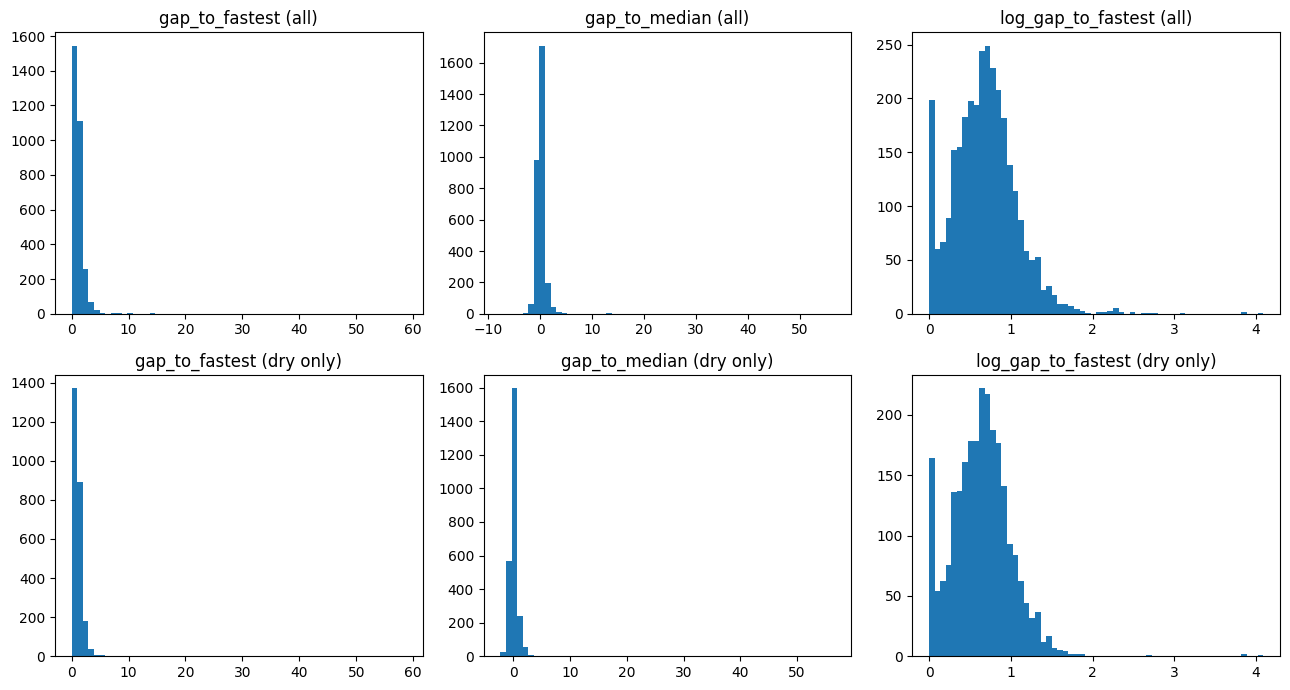

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for column, metric in enumerate(['gap_to_fastest', 'gap_to_median', 'log_gap_to_fastest']):
    axes[0, column].hist(driver_session[metric], bins=60)
    axes[0, column].set_title(f'{metric} (all)')
    axes[1, column].hist(dry_sessions[metric], bins=60)
    axes[1, column].set_title(f'{metric} (dry only)')
plt.tight_layout()
plt.show()

### It wasn't the zero floor, and it wasn't the rain

Measuring against the session median made the skew **worse**, 21.9 against 18.3. Restricting to dry
sessions made it worse again, 22.5 against 18.3.

So neither suspect is responsible. What is left is a handful of extreme laps in **dry** sessions that
the `iacc` flag still marks as good. Taking the logarithm of the gap would pull the skew down to
1.14, but reaching for a transform before knowing what those laps are would hide the problem rather
than solve it. So I go and look at them.

In [20]:
worst_gaps = driver_session.nlargest(15, 'gap_to_fastest')
print(worst_gaps[['season', 'gp', 'team', 'drv', 'best_lap', 'gap_to_fastest',
                  'n_valid_laps', 'rain_fraction']].round(2).to_string(index=False))
print()
for threshold in [10, 5, 3]:
    print(f'gap > {threshold}%:', (driver_session['gap_to_fastest'] > threshold).sum(),
          f'of {len(driver_session)}')

 season                       gp            team drv  best_lap  gap_to_fastest  n_valid_laps  rain_fraction
   2021     Abu Dhabi Grand Prix      AlphaTauri TSU    131.52           58.76             2           0.00
   2021        French Grand Prix    Aston Martin STR    132.58           45.70             1           0.00
   2023 Saudi Arabian Grand Prix        Williams SAR    128.51           44.78             1           0.00
   2020       Turkish Grand Prix        Williams LAT    141.61           20.54             1           0.12
   2018    Azerbaijan Grand Prix      Toro Rosso HAR    117.35           14.45             1           0.18
   2023    Azerbaijan Grand Prix      AlphaTauri DEV    115.28           13.84             1           0.00
   2020       Turkish Grand Prix    Haas F1 Team GRO    132.91           13.13             2           0.12
   2024       British Grand Prix          Alpine GAS     99.80           11.45             3           0.09
   2020       Turkish Grand 

In [21]:
is_outlier = driver_session['gap_to_fastest'] > 5
print('valid-lap count vs gap size:')
print(driver_session.groupby(is_outlier)['n_valid_laps']
      .describe()[['count', 'mean', 'min', '50%']].round(2))

valid-lap count vs gap size:
                 count  mean  min  50%
gap_to_fastest                        
False           3000.0  3.53  1.0  3.0
True              29.0  2.52  1.0  2.0


### The worst laps come from two different situations

1. **Sessions that fell apart.** The three worst rows (+58.8%, +45.7%, +44.8%) each come from a
   driver with only **1 or 2 valid laps**, in the dry: Tsunoda at Abu Dhabi 2021, Stroll in France
   2021, Sargeant in Saudi Arabia 2023. A dry lap 45% off pole is not slow pace, it is a wrecked lap
   that `iacc` still marked accurate. These outliers average 2.5 valid laps against 3.5 for everyone
   else.
2. **Sessions that were wet.** 2020 Turkey supplies 8 of the top 15 and 2024 Silverstone 2 more.
   Those gaps are *real*, so they are a question for the model rather than something to clean out.

## Outliers and the 107% rule

**Where is the line between a slow lap and a lap that does not represent the driver?**

F1 already draws one. **The 107% rule:** a driver who fails to lap within 107% of the fastest Q1 time
does not qualify for the race. Lapping within 107% of the fastest time is the same as being no more
than 7% off it, which is exactly the measure built above, so the rule becomes `gap_to_fastest <= 7`.
The sport treats that as the edge of a legitimate competitive lap, and it applies to exactly the
segment I am using. It is defensible in a way that "I dropped the top 1%" is not.

In [22]:
within_107 = driver_session['gap_to_fastest'] <= 7
print('excluded by 107% rule:', (~within_107).sum(), 'of', len(driver_session))
print()
print('excluded rows, by rain:')
excluded = driver_session[~within_107]
print('  wet sessions (rain > 0):', (excluded['rain_fraction'] > 0).sum())
print('  dry sessions:', (excluded['rain_fraction'] == 0).sum())
print()
print('median valid laps - excluded:', excluded['n_valid_laps'].median(),
      '| kept:', driver_session[within_107]['n_valid_laps'].median())

excluded by 107% rule: 21 of 3029

excluded rows, by rain:
  wet sessions (rain > 0): 17
  dry sessions: 4

median valid laps - excluded: 2.0 | kept: 3.0


In [23]:
qualified = driver_session[within_107]
qualified_dry = qualified[qualified['rain_fraction'].eq(0)]

for label, frame in [('all sessions', qualified), ('dry only', qualified_dry)]:
    gap = frame['gap_to_fastest']
    print(f'{label:14s} n={len(frame):5d}  skew={stats.skew(gap):6.2f}  '
          f'std={gap.std():5.3f}  median={gap.median():5.3f}  max={gap.max():6.3f}')

all sessions   n= 3008  skew=  1.63  std=0.828  median=0.954  max= 6.906
dry only       n= 2493  skew=  1.43  std=0.734  median=0.902  max= 5.611


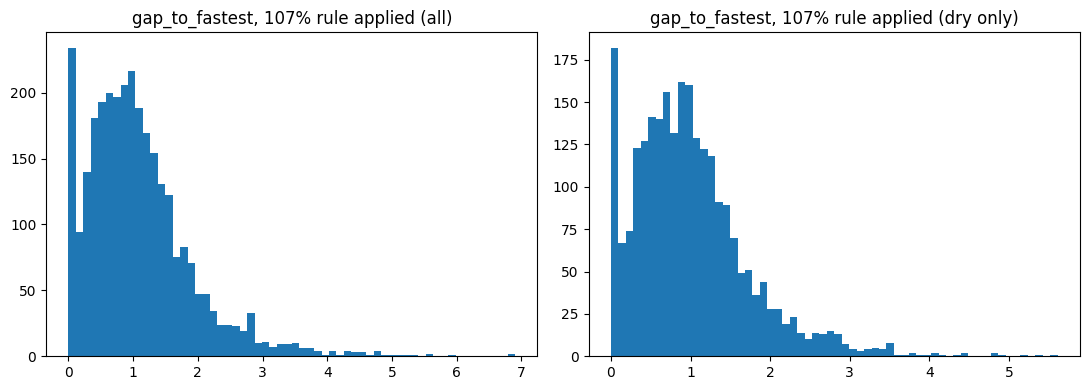

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(qualified['gap_to_fastest'], bins=60)
axes[0].set_title('gap_to_fastest, 107% rule applied (all)')
axes[1].hist(qualified_dry['gap_to_fastest'], bins=60)
axes[1].set_title('gap_to_fastest, 107% rule applied (dry only)')
plt.tight_layout()
plt.show()

### What the rule does to the data

| | before | after 107% rule |
|---|---|---|
| skew | 18.3 | **1.63** (dry: 1.43) |
| std dev | 1.905% | **0.828%** (dry: 0.734%) |
| maximum | 58.8% | 6.9% |
| rows removed | | **21 of 3,029 (0.7%)** |

The lopsidedness falls by a factor of ten while under 1% of the data goes, and it goes from the right
place: of the 21 rows removed, 17 are from wet sessions and 4 from dry ones, and they have a median
of 2 valid laps against 3 for the rows kept.

A remaining skew of 1.63 is workable. Which distribution to fit is not decided here. The modelling
notebook settles it, though **not by the model comparison this originally promised**: `az.compare()`
scores predictions of whatever quantity a model describes, and a transformed gap is a different
quantity on a different scale, so the transform branches cannot be ranked against each other that
way. Notebook 02 decides on posterior predictive shape instead. This notebook only records what the
candidate transforms look like.

In [25]:
qualified = qualified.copy()
qualified['log_gap'] = np.log1p(qualified['gap_to_fastest'])
qualified['sqrt_gap'] = np.sqrt(qualified['gap_to_fastest'])

for metric in ['gap_to_fastest', 'log_gap', 'sqrt_gap']:
    values = qualified[metric]
    print(f'{metric:16s} skew={stats.skew(values):6.2f}  std={values.std():6.3f}  '
          f'min={values.min():6.3f}  max={values.max():6.3f}')

gap_to_fastest   skew=  1.63  std= 0.828  min= 0.000  max= 6.906
log_gap          skew=  0.26  std= 0.364  min= 0.000  max= 2.068
sqrt_gap         skew= -0.10  std= 0.416  min= 0.000  max= 2.628


`sqrt` comes out almost symmetric (−0.10), `log1p` mildly right-skewed (0.26), and the untransformed
gap 1.63. All three are viable candidates for the model comparison.

## Saving the dataset

**One row per driver per session**, written to `q1_pace.csv`.

I keep **all** rows, including the 21 the 107% rule excludes and the wet sessions, and carry the
`within_107` and `rain_fraction` flags alongside. That way the "drop the wet sessions" and "apply the
107% rule" versions stay runnable as checks later, instead of one choice being baked irreversibly
into the file.

In [26]:
stage_a = driver_session.assign(within_107=within_107)[
    ['season', 'gp', 'team', 'drv', 'best_lap', 'n_valid_laps', 'sesT',
     'gap_to_fastest', 'rain_fraction', 'within_107']
]
# /kaggle/working only exists on Kaggle; fall back so the cell cannot raise locally
output_dir = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('.')
stage_a.to_csv(output_dir / 'q1_pace.csv', index=False)

print('saved q1_pace.csv:', stage_a.shape)
print('modelling rows (107% applied):', stage_a['within_107'].sum())
print('drivers:', stage_a['drv'].nunique(), '| constructors:', stage_a['team'].nunique(),
      '| seasons:', stage_a['season'].nunique())
print()
print('drivers per constructor count (identification for driver-vs-car separation):')
print(stage_a.groupby('drv')['team'].nunique().value_counts().sort_index())

saved q1_pace.csv: (3029, 10)
modelling rows (107% applied): 3008
drivers: 43 | constructors: 19 | seasons: 8

drivers per constructor count (identification for driver-vs-car separation):
team
1    20
2    11
3     6
4     3
5     3
Name: count, dtype: int64


## What this notebook establishes

1. **A lap counts only if `iacc == True` and `del == False`.** Applied to Miami 2023 the rule reaches
   the same verdict as the official classification on Verstappen's aborted Q3 lap, without being told
   the answer. The deletion half looked redundant on the first session, which had none, but there are
   **625 deleted laps** across the dataset.

2. **Segments are not comparable, so everything is measured in Q1.** In Miami 2023 the track gained
   about **0.46s** between Q1 and Q2 as rubber went down, and the field shrank **20 to 15 to 8**
   because reaching each segment depends on being fast. Both effects apply to every weekend, though
   only this session was measured.

3. **The teammate gap proves there is something to measure, but cannot be the thing measured.**
   Of the **1,491 pairs**, 91% matched on tyre compound and freshness. Two further figures each
   rest on a smaller set: the cleaned gap's standard deviation of **0.39%** on the 752 pairs that
   also ran Q2 together with both gaps under 2%, and the **0.35** correlation between segments on
   the pairs that set a gap in both. The signal is real but noisy from session to session. It is
   unusable as the target because subtracting one teammate from the other cancels the car out.

4. **F1's own 107% rule handles the outliers better than a statistical cutoff.** The raw skew of
   **18.3** came from dry laps 45% to 59% off pole that `iacc` still marked accurate, set by drivers
   with 1 or 2 valid laps. The sport's own threshold cuts the skew to **1.63** while dropping **21
   rows of 3,029 (0.7%)**.

5. **What lets the model separate a driver from their car is comparison, and drivers differ in how
   much of it they get.** **23 of the 43 drivers changed team** between 2018 and 2025: 11 drove for
   two teams, 6 for three, 3 for four and 3 for five. Each move puts two different cars on one scale
   through the same person.

   Moving is not the only route. A driver who stays at one team is still measured against whoever
   arrives in the other side of the garage, and those teammates have driven elsewhere. So the
   drivers to be careful about are the ones with few sessions or few teammates, which is not the same
   as the ones who never moved. Notebook 03 measures which of the two matters more.